In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from swiftlog_utils import load_problem, make_preprocessor, evaluate


Best params: {'select__k': 20, 'model__subsample': 0.6, 'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_depth': 4, 'model__learning_rate': 0.05}
CV ROC-AUC: 0.513 +/- 0.023
Validation ROC-AUC: 0.482
Chosen threshold: 0.37
Validation @0.5:   {'Accuracy': 0.615, 'Precision': 0.641, 'Recall': 0.92, 'F1': 0.756, 'ROC_AUC': 0.482}
Validation @thr:   {'Accuracy': 0.652, 'Precision': 0.651, 'Recall': 0.996, 'F1': 0.788, 'ROC_AUC': 0.482}

TEST tuned model: {'Accuracy': 0.655, 'Precision': 0.655, 'Recall': 0.998, 'F1': 0.791, 'ROC_AUC': 0.492}
TEST baseline (always Delayed): accuracy 0.655 | AUC 0.5


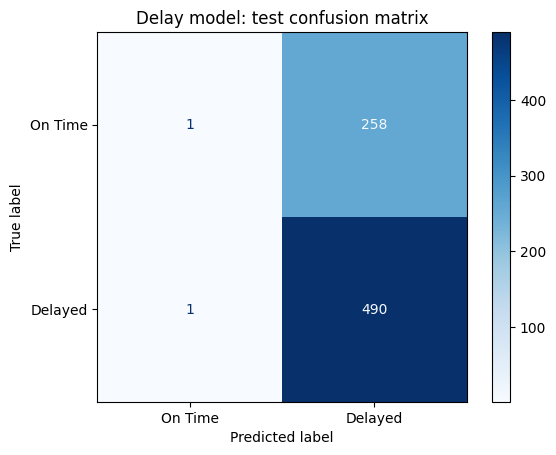

In [3]:
MODELS = Path("../Models"); FIG = Path("../Reports/figures")

cfg, sets = load_problem("delay")
Xtr, ytr = sets["train"]; Xva, yva = sets["val"]; Xte, yte = sets["test"]

pipe = Pipeline([("prep", make_preprocessor(cfg)),
                 ("select", SelectKBest(f_classif)),
                 ("model", GradientBoostingClassifier(random_state=42))])

params = {"select__k": [5, 10, 20, "all"],
          "model__n_estimators": [50, 100, 150, 200],
          "model__max_depth": [2, 3, 4],
          "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
          "model__subsample": [0.6, 0.8, 1.0],
          "model__min_samples_leaf": [10, 30, 60]}

search = RandomizedSearchCV(pipe, params, n_iter=25, cv=TimeSeriesSplit(5),
                            scoring="roc_auc", random_state=42, n_jobs=-1)
search.fit(Xtr, ytr)

best = search.best_estimator_
std = pd.DataFrame(search.cv_results_).loc[search.best_index_, "std_test_score"]
print("Best params:", search.best_params_)
print(f"CV ROC-AUC: {search.best_score_:.3f} +/- {std:.3f}")

p_va = best.predict_proba(Xva)[:, 1]
print("Validation ROC-AUC:", round(roc_auc_score(yva, p_va), 3))
ths = np.linspace(0.3, 0.8, 51)
thr = ths[int(np.argmax([balanced_accuracy_score(yva, p_va >= t) for t in ths]))]
print("Chosen threshold:", round(thr, 2))
print("Validation @0.5:  ", {k: round(v, 3) for k, v in evaluate("classification", yva, (p_va >= 0.5).astype(int), p_va).items()})
print("Validation @thr:  ", {k: round(v, 3) for k, v in evaluate("classification", yva, (p_va >= thr).astype(int), p_va).items()})

# Final one-time test evaluation
p_te = best.predict_proba(Xte)[:, 1]
pred_te = (p_te >= thr).astype(int)
test_res = evaluate("classification", yte, pred_te, p_te)
print("\nTEST tuned model:", {k: round(v, 3) for k, v in test_res.items()})
print("TEST baseline (always Delayed): accuracy", round(yte.mean(), 3), "| AUC 0.5")

cm = confusion_matrix(yte, pred_te)
ConfusionMatrixDisplay(cm, display_labels=["On Time", "Delayed"]).plot(cmap="Blues")
plt.title("Delay model: test confusion matrix")
plt.savefig(FIG / "cm_delay.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump({"pipeline": best, "threshold": float(thr), "features": cfg["num"] + cfg["cat"]},
            MODELS / "delay_model.joblib")
pd.DataFrame([{"Problem": "delay", "Model": "Gradient Boosting (tuned)", **test_res}]).round(3)\
  .to_csv(MODELS / "final_delay.csv", index=False)

In [4]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score
from swiftlog_utils import train_months

def month_folds(months):
    """Expanding window: train on earlier months, validate on the next one."""
    ms = sorted(months.unique())
    return [(np.where(months < ms[i])[0], np.where(months == ms[i])[0])
            for i in range(1, len(ms))]

SC = "neg_root_mean_squared_error"
final_rows = []

for name in ["demand", "customer", "warehouse"]:
    cfg, sets = load_problem(name)
    Xtr, ytr = sets["train"]; Xva, yva = sets["val"]; Xte, yte = sets["test"]
    cv = (KFold(5, shuffle=True, random_state=42) if name == "customer"
          else month_folds(train_months(name)))

    base = Pipeline([("prep", make_preprocessor(cfg)), ("m", DummyRegressor())])
    base_cv = -cross_val_score(base, Xtr, ytr, cv=cv, scoring=SC).mean()

    ridge = Pipeline([("prep", make_preprocessor(cfg)),
                      ("select", SelectKBest(f_regression)), ("model", Ridge())])
    gb = Pipeline([("prep", make_preprocessor(cfg)),
                   ("select", SelectKBest(f_regression)),
                   ("model", GradientBoostingRegressor(random_state=42))])
    searches = {
        "Ridge (tuned)": GridSearchCV(
            ridge, {"select__k": [3, 5, "all"], "model__alpha": [1, 10, 100, 1000]},
            cv=cv, scoring=SC, n_jobs=-1),
        "Gradient Boosting (tuned)": RandomizedSearchCV(
            gb, {"select__k": [3, 5, "all"], "model__n_estimators": [50, 100, 200],
                 "model__max_depth": [2, 3], "model__learning_rate": [0.01, 0.03, 0.05],
                 "model__subsample": [0.6, 0.8, 1.0], "model__min_samples_leaf": [5, 10, 20]},
            n_iter=15, cv=cv, scoring=SC, random_state=42, n_jobs=-1),
    }
    cv_rmse = {}
    for mname, s in searches.items():
        s.fit(Xtr, ytr)
        cv_rmse[mname] = -s.best_score_

    best_name = min(cv_rmse, key=cv_rmse.get)
    best_s = searches[best_name]
    best = best_s.best_estimator_

    print(f"\n{name.upper()}")
    print(f"  CV RMSE: baseline {base_cv:.3f} | " +
          " | ".join(f"{k} {v:.3f}" for k, v in cv_rmse.items()))
    print("  Best:", best_name, best_s.best_params_)
    print("  Validation:", {k: round(v, 3) for k, v in evaluate("regression", yva, best.predict(Xva)).items()})

    base.fit(Xtr, ytr)
    te = evaluate("regression", yte, best.predict(Xte))
    tb = evaluate("regression", yte, base.predict(Xte))
    print("  TEST tuned:   ", {k: round(v, 3) for k, v in te.items()})
    print("  TEST baseline:", {k: round(v, 3) for k, v in tb.items()})

    joblib.dump({"pipeline": best, "features": cfg["num"] + cfg["cat"]},
                MODELS / f"{name}_model.joblib")
    final_rows += [{"Problem": name, "Model": best_name, **te},
                   {"Problem": name, "Model": "Baseline (mean)", **tb}]

pd.DataFrame(final_rows).round(3).to_csv(MODELS / "final_regression.csv", index=False)


DEMAND
  CV RMSE: baseline 13.737 | Ridge (tuned) 13.725 | Gradient Boosting (tuned) 13.828
  Best: Ridge (tuned) {'model__alpha': 1000, 'select__k': 5}
  Validation: {'MAE': 10.674, 'MSE': 171.439, 'RMSE': np.float64(13.093), 'R2': -0.123}
  TEST tuned:    {'MAE': 11.342, 'MSE': 218.843, 'RMSE': np.float64(14.793), 'R2': -0.064}
  TEST baseline: {'MAE': 11.321, 'MSE': 218.835, 'RMSE': np.float64(14.793), 'R2': -0.064}

CUSTOMER
  CV RMSE: baseline 5921.685 | Ridge (tuned) 5889.945 | Gradient Boosting (tuned) 5935.361
  Best: Ridge (tuned) {'model__alpha': 100, 'select__k': 'all'}
  Validation: {'MAE': 4960.867, 'MSE': 37495997.558, 'RMSE': np.float64(6123.398), 'R2': 0.015}
  TEST tuned:    {'MAE': 4671.735, 'MSE': 37417071.543, 'RMSE': np.float64(6116.95), 'R2': -0.023}
  TEST baseline: {'MAE': 4662.55, 'MSE': 36584450.276, 'RMSE': np.float64(6048.508), 'R2': -0.001}

WAREHOUSE
  CV RMSE: baseline 0.072 | Ridge (tuned) 0.072 | Gradient Boosting (tuned) 0.072
  Best: Gradient Boostin

In [5]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
r1 = pd.read_csv(MODELS / "validation_results_round1.csv")
d_final = pd.read_csv(MODELS / "final_delay.csv")
r_final = pd.read_csv(MODELS / "final_regression.csv")

d_base = pd.DataFrame([{"Problem": "delay", "Model": "Baseline (always Delayed)",
    "Accuracy": round(yte.mean(), 3) if False else None}])
cfg_d, sets_d = load_problem("delay")
y_d = sets_d["test"][1]
base_pred = np.ones(len(y_d), dtype=int)
d_base = pd.DataFrame([{"Problem": "delay", "Model": "Baseline (always Delayed)",
                        **evaluate("classification", y_d, base_pred, np.full(len(y_d), 0.5))}])

final = pd.concat([d_final, d_base, r_final], ignore_index=True).round(3)

verdict = []
for p, g in final.groupby("Problem", sort=False):
    tuned = g.iloc[0]
    base = g[g["Model"].str.startswith("Baseline")].iloc[0]
    beats = (tuned["ROC_AUC"] > 0.55) if p == "delay" else (tuned["R2"] > base["R2"])
    verdict.append({"Problem": p, "Tuned model": tuned["Model"], "Beats baseline on test?": "Yes" if beats else "No"})
verdict = pd.DataFrame(verdict)
print(verdict.to_string(index=False))

with pd.ExcelWriter(MODELS / "Model_Comparison.xlsx") as xw:
    r1.to_excel(xw, sheet_name="Validation_Round1", index=False)
    final.to_excel(xw, sheet_name="Final_Test_Results", index=False)
    verdict.to_excel(xw, sheet_name="Verdict_vs_Baseline", index=False)

bundle = {n: joblib.load(MODELS / f"{n}_model.joblib")
          for n in ["delay", "demand", "customer", "warehouse"]}
joblib.dump(bundle, MODELS / "Best_Model.pkl")
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

  Problem               Tuned model Beats baseline on test?
    delay Gradient Boosting (tuned)                      No
   demand             Ridge (tuned)                      No
 customer             Ridge (tuned)                      No
warehouse Gradient Boosting (tuned)                      No
Saved: ['Best_Model.pkl', 'Model_Comparison.xlsx', 'customer_model.joblib', 'delay_model.joblib', 'demand_model.joblib', 'final_delay.csv', 'final_regression.csv', 'validation_results_round1.csv', 'warehouse_model.joblib']
